# Bulk ATAC-seq part 1: from reads to peaks

**Case study: How do FOXA1 and HNF4A change the chromatin of a blood cell line?**

Hansen JL, Loell KJ, Cohen BA. *A test of the pioneer factor hypothesis using ectopic liver gene activation.* eLife (2022) 11:e73358. https://doi.org/10.7554/eLife.73358

This is the same study as the [bulk RNA-seq practical](../bulk-rna-seq/index.md): there we saw which genes FOXA1 and HNF4A switch on; here we look at what they do to the chromatin.

**Research questions:**

1. How good are the ATAC-seq libraries?
2. Which regions open (or close) when FOXA1 and HNF4A are expressed?
3. Do the opened regions contain FOXA1 and HNF4A motifs, and do they lie near the genes that are switched on?

We answer the first question in this notebook and the other two in [part 2](part_2_consensus_peaks_macs_diff.ipynb) and [part 3](part_3_diffbind_deseq2.ipynb).

## Introduction

When transcription factors (TFs) and other proteins bind DNA, they displace nucleosomes and make the chromatin **accessible**. ATAC-seq (Assay for Transposase-Accessible Chromatin with sequencing) profiles these regions with the hyperactive **Tn5 transposase**: Tn5 cuts accessible DNA and inserts sequencing adapters in a single step ("tagmentation"). Each DNA fragment between two insertion sites is sequenced from both ends (paired-end).

Two properties of ATAC-seq data guide the whole analysis:

- **Fragment lengths are not random.** Short fragments (< 100 bp) come from nucleosome-free DNA, often where TFs bind. Longer fragments of ~200, ~400, ~600 bp span one, two or three nucleosomes. A good library shows this *nucleosome ladder*.
- **Signal concentrates at regulatory elements**: promoters (around transcription start sites, TSSs) and enhancers. A good library has much more signal at TSSs than in the flanking DNA (*TSS enrichment*).

In this notebook we go from raw reads to peaks for two samples:

1. read quality (FastQC)
2. adapter trimming (fastp)
3. alignment (bowtie2)
4. duplicate marking (Picard)
5. filtering
6. ATAC-specific quality control: mitochondrial reads, fragment sizes, coverage tracks and TSS enrichment
7. peak calling (MACS3) and fraction of reads in peaks
8. looking at the data

The next notebooks use all four samples of the experiment: consensus peaks and MACS3 differential analysis ([part 2](part_2_consensus_peaks_macs_diff.ipynb)), then DiffBind and DESeq2, motifs and the link with gene expression ([part 3](part_3_diffbind_deseq2.ipynb)).

Additional resources:

- [From reads to insight: a hitchhiker's guide to ATAC-seq data analysis](https://genomebiology.biomedcentral.com/articles/10.1186/s13059-020-1929-3) (Yan et al., 2020)
- [Harvard FAS Informatics - ATAC-seq Guidelines](https://github.com/harvardinformatics/ATAC-seq)
- [ENCODE ATAC-seq pipeline](https://github.com/ENCODE-DCC/atac-seq-pipeline) and its [quality standards](https://www.encodeproject.org/atac-seq/)
- Buenrostro et al., 2013 (the original ATAC-seq paper) and Corces et al., 2017 (Omni-ATAC)

## The dataset

In the liver, FOXA1 is the textbook example of a **pioneer factor**: a TF that can bind closed chromatin and open it, so that other TFs, such as HNF4A, can bind. Hansen et al. tested this idea outside the liver. They made K562 cells (a leukemia cell line, in which liver genes are silent) in which FOXA1, HNF4A or both can be switched on by adding doxycycline (dox) to the medium, and measured gene expression (RNA-seq) and chromatin accessibility (ATAC-seq) without and with dox.

We use the ATAC-seq data of the line that expresses **both FOXA1 and HNF4A** ([GSE182188](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE182188)):

| sample | dox | replicate |
|---|---|---|
| FOXA1HNF4A_U1, FOXA1HNF4A_U2 | no (uninduced) | 2 |
| FOXA1HNF4A_I1, FOXA1HNF4A_I2 | yes (induced) | 2 |

Each library was sequenced paired-end (2 × 75 bp) to about 90-115 million read pairs.

In this notebook we follow **two samples**, one uninduced (`FOXA1HNF4A_U1`) and one induced (`FOXA1HNF4A_I1`). To keep everything fast, we only use the read pairs that come from **chromosome 17** (about 2.7% of the genome). Chromosome 17 holds several liver genes that FOXA1 and HNF4A switch on in the RNA-seq practical (*ASGR1*, *VTN*, *SHBG*, *SERPINF2*). The genome-wide results for all four samples have been generated with exactly the same steps; we use them in the next notebooks.

## Software

All command-line tools of parts 1 and 2 (FastQC, fastp, bowtie2, samtools, Picard, deepTools, MACS3, ataqv, bedtools, subread, and sra-tools for downloading) can be installed in a single mamba environment. This environment also contains `bash_kernel`, which lets us run bash commands in a Jupyter notebook. Create it once, in a terminal (not in this notebook):

```
mamba create -n atac-cli -c conda-forge -c bioconda python=3.11 sra-tools fastqc fastp multiqc bowtie2 samtools picard macs3 bedtools subread deeptools ucsc-bedgraphtobigwig ataqv seqkit bash_kernel
```

To use this environment in Jupyter we register it as a *kernel*:

```
mamba activate atac-cli
KERNEL_DIR=$(jupyter --data-dir)/kernels/atac-cli
mkdir -p ${KERNEL_DIR}
cat > ${KERNEL_DIR}/kernel.json << EOF
{
  "argv": ["${CONDA_PREFIX}/bin/python", "-m", "bash_kernel", "-f", "{connection_file}"],
  "display_name": "Bash (atac-cli)",
  "language": "bash",
  "env": {"PATH": "${CONDA_PREFIX}/bin:/usr/local/bin:/usr/bin:/bin", "PS1": "$"}
}
EOF
jupyter kernelspec list   # the kernel atac-cli should be listed
```

We add the `bin` folder of the environment to the `PATH`, so the tools are found even when Jupyter itself runs from another environment. Then (re)start Jupyter and select the kernel "Bash (atac-cli)".

The data (genome and bowtie2 index, chr17 reads, pre-generated results) are ready for you in the course data on the teaching server (see Step 0); the [topic page](index.md) explains how to prepare them yourself.

## Step 0: Setup

We work in the folder `data`, next to this notebook: everything we make in this notebook goes to `data/part_1`.

The **course data** (genome, reads, pre-generated results) were prepared by the teachers and are in a shared folder on the teaching server, `/data/teachers/data/bulk_atac_seq/hansen_foxa1_hnf4a`. You can read the files there, but not change them, and you don't need to copy them: the notebooks read them where they are, through the variable `BULK`. If this folder doesn't exist (for example on your own computer), the notebooks use the folder `course_data` next to this notebook instead.

The reference files (hg38) are already in the subfolder `genome/hg38` of the course data: the bowtie2 index of the whole genome, the sequence of chromosome 17, the chromosome sizes and the blacklist. We align to the whole genome, so that reads can map to the place they really come from, but we only need the sequence of chr17 later (all our reads and peaks are on chr17). The files were downloaded with the code below (also in `scripts/00_download_refs.sh`, see the [topic page](index.md)); it is shown as text, **don't run it**: the bowtie2 index is about 5 GB.

```bash
mkdir -p course_data/genome/hg38 && cd course_data/genome/hg38
# sequence of chr17 and chromosome sizes (UCSC)
wget https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr17.fa.gz
wget https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.chrom.sizes
gunzip chr17.fa.gz && samtools faidx chr17.fa
# ENCODE blacklist v2: regions with artificially high signal
wget https://github.com/Boyle-Lab/Blacklist/raw/master/lists/hg38-blacklist.v2.bed.gz
zcat hg38-blacklist.v2.bed.gz | cut -f1-3 > hg38-blacklist.v2.bed && rm hg38-blacklist.v2.bed.gz
# prebuilt bowtie2 index of the primary assembly without alternative haplotypes (building it yourself takes a few hours)
mkdir -p bowtie2 && cd bowtie2
wget https://genome-idx.s3.amazonaws.com/bt/GRCh38_noalt_as.zip && unzip GRCh38_noalt_as.zip && rm GRCh38_noalt_as.zip
```

The next cell defines where the course data are and creates our working folder. Run it again whenever you restart the notebook.

In [1]:
# The folder of this notebook (the kernel starts there). Kept when you run this cell again after the cd below.
HERE=${HERE:-$PWD}

# Course data (read-only): the shared folder on the teaching server, otherwise the folder course_data next to this notebook
BULK=/data/teachers/data/bulk_atac_seq/hansen_foxa1_hnf4a
[ -d $BULK ] || BULK=$HERE/course_data
GENOME=$BULK/genome/hg38

# Your own working folder, in the folder data next to this notebook
OUT=$HERE/data/part_1
mkdir -p $OUT && cd $OUT

THREADS=4
SAMPLES="FOXA1HNF4A_U1 FOXA1HNF4A_I1"
echo "course data: ${BULK#$HERE/}"
echo "my folder:   ${OUT#$HERE/}"

course data: course_data
my folder:   data/part_1


### The sample sheet

The data are deposited in the Gene Expression Omnibus (GEO) under accession number GSE182188:

https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE182188

This GEO series contains the ATAC-seq of all three cell lines; we only use the four samples of the FOXA1-HNF4A line. On the GEO page, click on "SRA Run Selector" at the bottom of the page. This shows a table with all sequencing runs (SRR numbers) of the series, with their metadata. We copy what we need into a **sample sheet**: one row per sample, with its name, its SRA run, its title on GEO and the experimental factors. The next notebooks use the same samples.

In [3]:
# printf uses the format (6 values separated by tabs, \t, then a newline, \n) again for every 6 values;
# quotes keep the GEO titles, which contain spaces, together as one value
printf "%s\t%s\t%s\t%s\t%s\t%s\n" \
    sample        run         gsm_title                            line       dox       replicate \
    FOXA1HNF4A_U1 SRR15477356 "ATACseq FoxA1-Hnf4a uninduced rep1" FOXA1HNF4A uninduced 1 \
    FOXA1HNF4A_U2 SRR15477358 "ATACseq FoxA1-Hnf4a uninduced rep2" FOXA1HNF4A uninduced 2 \
    FOXA1HNF4A_I1 SRR15477360 "ATACseq FoxA1-Hnf4a induced rep1"   FOXA1HNF4A induced   1 \
    FOXA1HNF4A_I2 SRR15477362 "ATACseq FoxA1-Hnf4a induced rep2"   FOXA1HNF4A induced   2 \
    > samplesheet.tsv
# -s $'\t': split columns on tabs only (the GEO titles contain spaces)
column -t -s $'\t' samplesheet.tsv

sample         run          gsm_title                           line        dox        replicate
FOXA1HNF4A_U1  SRR15477356  ATACseq FoxA1-Hnf4a uninduced rep1  FOXA1HNF4A  uninduced  1
FOXA1HNF4A_U2  SRR15477358  ATACseq FoxA1-Hnf4a uninduced rep2  FOXA1HNF4A  uninduced  2
FOXA1HNF4A_I1  SRR15477360  ATACseq FoxA1-Hnf4a induced rep1    FOXA1HNF4A  induced    1
FOXA1HNF4A_I2  SRR15477362  ATACseq FoxA1-Hnf4a induced rep2    FOXA1HNF4A  induced    2


### Getting the reads

The raw reads are on SRA; the sample sheet links each sample to its SRA run (`run` column). The code below downloads the full FASTQ files of all four samples into the folder `course_data_build` (next to `course_data`; it holds the files that are only needed to prepare the course data). **Don't run it during the practical**: each sample is about 11-13 GB compressed (47 GB in total) and the download takes hours. It is shown as text on purpose; to run it, copy it to a terminal in this folder (with the `atac-cli` environment active), or use `scripts/02_download_bulk.sh`, which downloads the same files from the European Nucleotide Archive and checks them.

```bash
mkdir -p course_data_build/raw
# skip the header line of the sample sheet written above; columns 1 and 2 are the sample name and the SRA run
tail -n +2 data/part_1/samplesheet.tsv | while read SAMPLE RUN rest; do
    prefetch $RUN -O course_data_build/raw --max-size 30g                                # download the .sra file
    fasterq-dump course_data_build/raw/$RUN --split-files -e 4 -O course_data_build/raw  # convert to RUN_1.fastq and RUN_2.fastq
    gzip course_data_build/raw/${RUN}_1.fastq course_data_build/raw/${RUN}_2.fastq
    rm -r course_data_build/raw/$RUN                                                     # the .sra file is no longer needed
done
```

`scripts/10_bulk_pipeline.sh` then runs the steps of this notebook on the full data of every sample.

Here we use only the read pairs that align to chr17, extracted from the full data by `scripts/10_bulk_pipeline.sh`. Let's link those of our two samples into our folder. Each sample has two files: `R1` (first read of each pair) and `R2` (second read).

In [2]:
for s in $SAMPLES; do ln -sf $BULK/fastq_chr17/${s}_chr17_R?.fastq.gz .; done
# -l: long listing, -h: human-readable sizes, -L: follow the links, -g -G: don't show the owner and group
ls -lhLgG *_chr17_R?.fastq.gz

-rw-r--r-- 1 145M Oct 29 05:48 FOXA1HNF4A_I1_chr17_R1.fastq.gz
-rw-r--r-- 1 146M Oct 29 05:49 FOXA1HNF4A_I1_chr17_R2.fastq.gz
-rw-r--r-- 1 105M Oct 29 05:47 FOXA1HNF4A_U1_chr17_R1.fastq.gz
-rw-r--r-- 1 109M Oct 29 05:48 FOXA1HNF4A_U1_chr17_R2.fastq.gz


A FASTQ file has four lines per read: name, sequence, `+`, and base qualities. Let's look at the first read and count the read pairs:

In [4]:
# zcat: decompress to the screen; head -4: the first read (4 lines)
zcat FOXA1HNF4A_U1_chr17_R1.fastq.gz | head -4
for s in $SAMPLES; do
    echo "$s: $(( $(zcat ${s}_chr17_R1.fastq.gz | wc -l) / 4 )) read pairs"
done

@SRR15477356.65 NS500153:674:HTFN3BGXH:1:11101:5263:1046/1
GTTCCNCTCGCCGCGGACCGACCGGGCAGGGCCAACCCAGGACTGTTCCGGGGAGGGGAGCAGGGTAGGGGAGCG
+
AAAAA#AEEEAEEAEE6AEE6EEEEEEEEEEEEA6AEEEEE6AEEEE6EEEEEEEAEEAEE/EEE/AEEEE/E/A
FOXA1HNF4A_U1: 2114641 read pairs
FOXA1HNF4A_I1: 2894492 read pairs


## Step 1: Read quality (FastQC)

FastQC summarises the quality of a FASTQ file: base qualities along the read, GC content, duplication, over-represented sequences and adapter content. It writes an HTML report per file; open them from the file browser on the left.

In [5]:
mkdir -p fastqc_raw
# -q: quiet (no progress messages); -t: number of files processed in parallel
fastqc -q -t $THREADS --outdir fastqc_raw *_chr17_R?.fastq.gz
ls fastqc_raw

FOXA1HNF4A_I1_chr17_R1_fastqc.html  FOXA1HNF4A_U1_chr17_R1_fastqc.html
FOXA1HNF4A_I1_chr17_R1_fastqc.zip   FOXA1HNF4A_U1_chr17_R1_fastqc.zip
FOXA1HNF4A_I1_chr17_R2_fastqc.html  FOXA1HNF4A_U1_chr17_R2_fastqc.html
FOXA1HNF4A_I1_chr17_R2_fastqc.zip   FOXA1HNF4A_U1_chr17_R2_fastqc.zip


Each report also contains a one-line verdict per module (`PASS`, `WARN` or `FAIL`). We can print these without opening the HTML:

In [6]:
for z in fastqc_raw/*_fastqc.zip; do
    echo "== $(basename $z _fastqc.zip)"
    # unzip -p: print a file from the zip archive without extracting it; show only the modules that did not pass
    unzip -p $z '*/summary.txt' | cut -f1,2 | grep -v PASS
done

== FOXA1HNF4A_I1_chr17_R1
FAIL	Per base sequence content
WARN	Sequence Duplication Levels
WARN	Overrepresented sequences
FAIL	Adapter Content
== FOXA1HNF4A_I1_chr17_R2
FAIL	Per base sequence content
WARN	Sequence Duplication Levels
WARN	Overrepresented sequences
FAIL	Adapter Content
== FOXA1HNF4A_U1_chr17_R1
FAIL	Per base sequence content
WARN	Overrepresented sequences
FAIL	Adapter Content
== FOXA1HNF4A_U1_chr17_R2
FAIL	Per base sequence content
WARN	Overrepresented sequences
FAIL	Adapter Content


**Question**: Open the HTML report of `FOXA1HNF4A_U1_chr17_R1`. Look at "Per base sequence quality" and "Adapter Content". Why do we expect adapters in ATAC-seq reads, even short ones of 75 bp? (Hint: how long are the DNA fragments between two Tn5 insertions?)

## Step 2: Adapter trimming (fastp)

Adapter sequence at the end of a read does not exist in the genome and lowers the alignment rate, so we remove it. You can use fastp, cutadapt, Trimmomatic, Trim Galore, etc. Here we use [fastp](https://github.com/OpenGene/fastp): for paired-end data it finds adapters by overlapping R1 and R2, so we don't even need to tell it the adapter sequence. Reads shorter than 25 bp after trimming are discarded (`--length_required 25`).

In [8]:
for s in $SAMPLES; do
    # -w: threads; -i/-I: input read 1/2; -o/-O: output read 1/2; -j/-h: JSON and HTML reports
    fastp -w $THREADS --detect_adapter_for_pe --length_required 25 \
        -i ${s}_chr17_R1.fastq.gz -I ${s}_chr17_R2.fastq.gz \
        -o ${s}_trimmed_R1.fastq.gz -O ${s}_trimmed_R2.fastq.gz \
        -j ${s}.fastp.json -h ${s}.fastp.html 2> ${s}.fastp.log
    echo "== $s"
    grep -E "reads passed filter|reads with adapter trimmed|Insert size peak" ${s}.fastp.log
done

== FOXA1HNF4A_U1
reads passed filter: 4229282
reads with adapter trimmed: 882235
Insert size peak (evaluated by paired-end reads): 45
== FOXA1HNF4A_I1
reads passed filter: 5788984
reads with adapter trimmed: 1241134
Insert size peak (evaluated by paired-end reads): 54


fastp also reports the **insert size** (the fragment length), estimated from the overlap of R1 and R2. Open `FOXA1HNF4A_U1.fastp.html` and look at the insert size distribution. With reads of 75 bp, R1 and R2 only overlap when the fragment is shorter than about 140 bp, so fastp sees only the nucleosome-free fragments; we look at the full distribution after the alignment (Step 6).

## Step 3: Alignment (bowtie2)

We align the trimmed read pairs to the human genome (hg38) with [bowtie2](https://bowtie-bio.sourceforge.net/bowtie2/manual.shtml). Three parameters matter here:

- `--very-sensitive`: a slower but more thorough search, standard for ATAC-seq.
- `-X 2000`: the maximum fragment length for a *proper pair*. The default (500) would throw away fragments spanning two or more nucleosomes.
- `--rg-id` / `--rg SM:`: a **read group** naming the sample. Many downstream tools (Picard, GATK) require one.

bowtie2 writes SAM to its standard output; we pipe it straight into `samtools sort` to get a coordinate-sorted BAM, and index it so other tools (and IGV) can jump to any region.

Note that we align to the **whole genome**, not just chr17. That is what you always do in practice: a read can only be trusted as "unique" if it was compared against everything else. This takes about 10-15 minutes per sample.

In [9]:
for s in $SAMPLES; do
    # -x: prefix of the genome index; -1/-2: read 1 and read 2; the summary goes to stderr (2>)
    # samtools sort -@ 2: 2 extra threads; "-": read the alignments from the pipe
    bowtie2 -p $THREADS --very-sensitive -X 2000 --rg-id $s --rg SM:$s -x $GENOME/bowtie2/GRCh38_noalt_as \
        -1 ${s}_trimmed_R1.fastq.gz -2 ${s}_trimmed_R2.fastq.gz 2> ${s}.bowtie2.log \
        | samtools sort -@ 2 -o ${s}.sorted.bam -
    samtools index ${s}.sorted.bam
    echo "== $s"; cat ${s}.bowtie2.log
done

[bam_sort_core] merging from 0 files and 2 in-memory blocks...
== FOXA1HNF4A_U1
2114641 reads; of these:
  2114641 (100.00%) were paired; of these:
    51988 (2.46%) aligned concordantly 0 times
    1734138 (82.01%) aligned concordantly exactly 1 time
    328515 (15.54%) aligned concordantly >1 times
    ----
    51988 pairs aligned concordantly 0 times; of these:
      24881 (47.86%) aligned discordantly 1 time
    ----
    27107 pairs aligned 0 times concordantly or discordantly; of these:
      54214 mates make up the pairs; of these:
        18060 (33.31%) aligned 0 times
        23203 (42.80%) aligned exactly 1 time
        12951 (23.89%) aligned >1 times
99.57% overall alignment rate
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
== FOXA1HNF4A_I1
2894492 reads; of these:
  2894492 (100.00%) were paired; of these:
    49981 (1.73%) aligned concordantly 0 times
    2428828 (83.91%) aligned concordantly exactly 1 time
    415683 (14.36%) aligned concordantly >1 times

*If the alignment takes too long, you can continue with the pre-generated files instead:*

```bash
ln -sf $BULK/nb01_generated/*.sorted.bam* .
```

The bowtie2 summary tells us how many pairs aligned **concordantly** (both mates, in the expected orientation and distance) exactly once or more than once (multi-mapping reads, e.g. in repeats).

A BAM file stores one line per read. Let's look at the first few alignments; the columns are read name, FLAG, chromosome, position, mapping quality (MAPQ), CIGAR, mate chromosome, mate position, fragment length (TLEN), sequence, qualities:

In [10]:
# the first 4 reads on chr17, columns 1-9 (sequence and qualities are long)
samtools view FOXA1HNF4A_U1.sorted.bam chr17 | head -4 | cut -f1-9

SRR15477356.46301018	99	chr17	60015	1	75M	=	60515	575
SRR15477356.46183369	163	chr17	60058	1	49M	=	60058	49
SRR15477356.46183369	83	chr17	60058	1	49M	=	60058	-49
SRR15477356.31091467	99	chr17	60068	1	75M	=	60336	343


The FLAG is a sum of bits that describe the read (paired, properly paired, unmapped, reverse strand, first/second in pair, secondary, duplicate, ...). The [Explain SAM flags](https://broadinstitute.github.io/picard/explain-flags.html) page decodes any value, and `samtools flags` does the same on the command line:

In [11]:
samtools flags 99
samtools flags 147

0x63	99	PAIRED,PROPER_PAIR,MREVERSE,READ1
0x93	147	PAIRED,PROPER_PAIR,REVERSE,READ2


## Step 4: Duplicate marking (Picard)

PCR amplification during library preparation creates identical copies of the same fragment. In paired-end data, duplicates are read pairs with the **same start and end position** of the fragment. They don't add information and can create artificial peaks, so we mark them with Picard `MarkDuplicates` (flag 1024) and remove them in the filtering step.

Marking first and filtering later matters: `samtools view -F 1024` only removes reads that a tool has *marked* as duplicates. Without this step, nothing would be removed.

(`--READ_NAME_REGEX null` tells Picard that the read names from SRA no longer contain the flow-cell coordinates it would use to find *optical* duplicates.)

In [12]:
for s in $SAMPLES; do
    # -Xmx4g: give Java 4 GB of memory; -M: the metrics file with the duplication rate
    # --VALIDATION_STRINGENCY LENIENT: warn about, but don't stop at, minor format issues
    picard -Xmx4g MarkDuplicates --QUIET true --VALIDATION_STRINGENCY LENIENT --READ_NAME_REGEX null \
        -I ${s}.sorted.bam -O ${s}.markdup.bam -M ${s}.markdup_metrics.txt 2> ${s}.markdup.log
    samtools index ${s}.markdup.bam
done
# print the duplication rate from the metrics table
for s in $SAMPLES; do
    grep -A1 "^LIBRARY" ${s}.markdup_metrics.txt \
        | awk -F'\t' -v s=$s 'NR==1 {for (i=1; i<=NF; i++) col[$i]=i}
                              NR==2 {printf "%s: %d read pairs, %.1f%% duplicates\n", s, $col["READ_PAIRS_EXAMINED"], 100*$col["PERCENT_DUPLICATION"]}'
done

FOXA1HNF4A_U1: 2096581 read pairs, 16.5% duplicates
FOXA1HNF4A_I1: 2873342 read pairs, 29.0% duplicates


## Step 5: Filtering

Not every aligned read is useful. We keep only read pairs that are:

| filter | samtools option | why |
|---|---|---|
| properly paired | `-f 2` | both mates aligned in the expected orientation and distance |
| not unmapped (4), mate not unmapped (8), not secondary (256), not QC-failed (512), not duplicate (1024), not supplementary (2048) | `-F 3852` (= 4 + 8 + 256 + 512 + 1024 + 2048) | |
| uniquely placed | `-q 30` | MAPQ ≥ 30: the aligner is confident about the position (multi-mappers get a low MAPQ) |
| on the main chromosomes, **not chrM** | list of chromosomes | mitochondrial DNA is not chromatinised, so Tn5 loves it; these reads say nothing about nuclear chromatin |
| outside the ENCODE **blacklist** | `bedtools intersect -v` | regions with artificially high signal in every experiment (repeats, satellites) |

In [13]:
# main chromosomes: chr1-22, chrX, chrY (no chrM, no unplaced contigs)
CHROMS=$(grep -E '^chr([0-9]+|X|Y)\s' $GENOME/hg38.chrom.sizes | cut -f1 | tr '\n' ' ')
echo $CHROMS

for s in $SAMPLES; do
    # -b: write BAM; -f/-F/-q: the filters of the table above; $CHROMS: only these chromosomes
    # bedtools intersect -v: keep reads that do NOT overlap the blacklist (-abam stdin: read the BAM from the pipe)
    samtools view -b -f 2 -F 3852 -q 30 ${s}.markdup.bam $CHROMS \
        | bedtools intersect -v -abam stdin -b $GENOME/hg38-blacklist.v2.bed > ${s}.unsorted.bam
    samtools sort -@ 2 -o ${s}.filtered.bam ${s}.unsorted.bam && rm ${s}.unsorted.bam
    samtools index ${s}.filtered.bam
    echo "$s: $(samtools view -c ${s}.markdup.bam) reads before, $(samtools view -c ${s}.filtered.bam) after filtering"
done

chr1 chr2 chr3 chr4 chr5 chr6 chr7 chrX chr8 chr9 chr11 chr10 chr12 chr13 chr14 chr15 chr16 chr17 chr18 chr20 chr19 chrY chr22 chr21
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
FOXA1HNF4A_U1: 4229282 reads before, 3101290 after filtering
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
FOXA1HNF4A_I1: 5788984 reads before, 3628253 after filtering


## Step 6: ATAC-specific quality control

### 6a. Mitochondrial reads

In our chr17 subset there are (almost) no mitochondrial reads, because we selected pairs that align to chr17. In a real ATAC-seq library the fraction of reads on chrM is an important quality measure: with the original protocol it could be 30-60%; with Omni-ATAC and good nuclei isolation it is usually below 10-20%. These reads are sequenced but useless.

Here are the genome-wide numbers for all four samples, from the full data (`samtools idxstats` lists the number of mapped reads per chromosome):

In [7]:
# idxstats columns: chromosome, length, mapped reads, unmapped reads
for f in $BULK/data_generated/*/*.markdup.idxstats; do
    awk -v s=$(basename $f .markdup.idxstats) '$1 == "chrM" {m = $3} {t += $3}
        END {printf "%-14s %5.1f%% of %d mapped reads on chrM\n", s, 100*m/t, t}' $f
done

FOXA1HNF4A_I1   17.7% of 213991722 mapped reads on chrM
FOXA1HNF4A_I2   25.9% of 194950051 mapped reads on chrM
FOXA1HNF4A_U1   23.8% of 179077988 mapped reads on chrM
FOXA1HNF4A_U2   29.5% of 223373434 mapped reads on chrM


### 6b. Fragment size distribution

For each read pair, the fragment length is in column 9 of the BAM (TLEN). deepTools `bamPEFragmentSize` plots the distribution. To be fast it only samples reads in small bins spread over the genome; its default spacing is made for whole genomes and would leave us only a few thousand fragments from chr17, so we sample more densely (`--distanceBetweenBins 10000`). This takes about 2 minutes. Look for the nucleosome-free peak below 100 bp and the mono-, di- and tri-nucleosome peaks at ~200, ~400 and ~600 bp. The small ~10 bp ripples on the short fragments come from the helical pitch of DNA: Tn5 cuts more easily on the side of the helix facing away from the nucleosome.

Sample    label:              FOXA1HNF4A_U1
Sample    size:               148600
Fragment  lengths:            
Min.:     26.0                
1st       Qu.:                85.0
Mean:     204.80610363391656  
Median:   180.0               
3rd       Qu.:                280.0
Max.:     1928.0              
Std:      141.92697964885912  
MAD:      96.0                
Len.      10%:                54.0
Len.      20%:                74.0
Len.      30%:                97.0
Len.      40%:                132.0
Len.      60%:                216.0
Len.      70%:                252.0
Len.      80%:                322.0
Len.      90%:                414.0
Len.      99%:                614.0
Read      lengths:            
Sample    size:               148600
Min.:     26.0                
1st       Qu.:                75.0
Mean:     70.78800134589503   
Median:   75.0                
3rd       Qu.:                75.0
Max.:     75.0                
Std:      9.757179227442991   
MAD:      0.0    

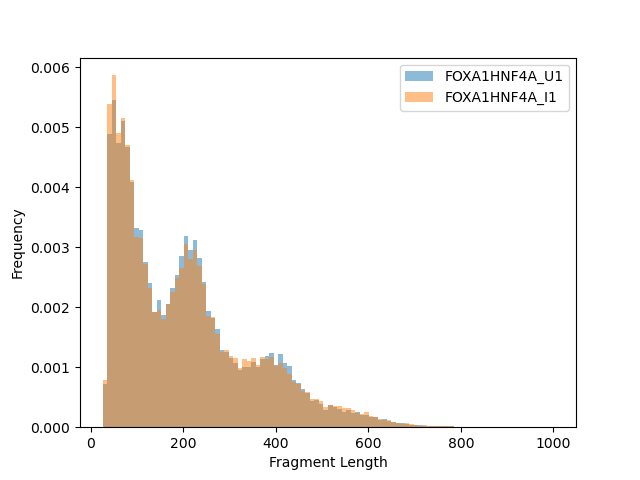

In [2]:
# --maxFragmentLength 1000: plot fragments up to 1 kb; --histogram: write the plot; the table (stdout) has the summary statistics
bamPEFragmentSize -p $THREADS -b FOXA1HNF4A_U1.filtered.bam FOXA1HNF4A_I1.filtered.bam --samplesLabel $SAMPLES \
    --maxFragmentLength 1000 --binSize 1000 --distanceBetweenBins 10000 --histogram fragment_sizes.png > fragment_sizes.txt 2> /dev/null
cat fragment_sizes.png | display
cut -f1-6 fragment_sizes.txt | column -t

### 6c. Coverage tracks

To check signal at TSSs, and later to look at the data in a genome browser, we need coverage tracks. A BAM file is too large and detailed to compare samples in a browser. A **bigWig** file stores the coverage (number of fragments overlapping each bin) and can be **normalised** so that samples with different sequencing depths become comparable.

We use deepTools `bamCoverage` with:

- `--extendReads`: count the whole fragment (from the paired reads), not just the reads.
- `--normalizeUsing RPGC` (reads per genomic content): scale coverage to 1× sequencing depth. This needs the *effective genome size*, the part of the genome reads can map to. Our reads only cover chr17, so we use the number of non-N bases of chr17.
- `--binSize 10`: the resolution of the track.

In [3]:
# effective genome size: non-N bases of chr17
GSIZE=$(samtools faidx $GENOME/chr17.fa chr17 | grep -v '>' | tr -d 'Nn\n' | wc -c)
echo "chr17 effective size: $GSIZE bp"

for s in $SAMPLES; do
    bamCoverage -p $THREADS -b ${s}.filtered.bam -o ${s}.bw --region chr17 \
        --extendReads --normalizeUsing RPGC --effectiveGenomeSize $GSIZE --binSize 10 2> /dev/null
done
ls -lhgG *.bw

chr17 effective size: 82920204 bp
-rw-r--r-- 1 7.3M Oct 29 16:04 FOXA1HNF4A_I1.bw
-rw-r--r-- 1 7.7M Oct 29 16:04 FOXA1HNF4A_U1.bw


### 6d. TSS enrichment

With the bigWig files we can check the second ATAC hallmark: signal around transcription start sites. `computeMatrix` collects the coverage in a ±2 kb window around every chr17 TSS, and `plotProfile` averages it. The **TSS enrichment score** is the signal at the TSS divided by the signal at the flanks. Exact values depend on how a tool computes it (window sizes, TSS annotation); as a rule of thumb ENCODE flags human samples below 5 as concerning and considers values above 7 ideal.

1186 protein-coding TSSs on chr17


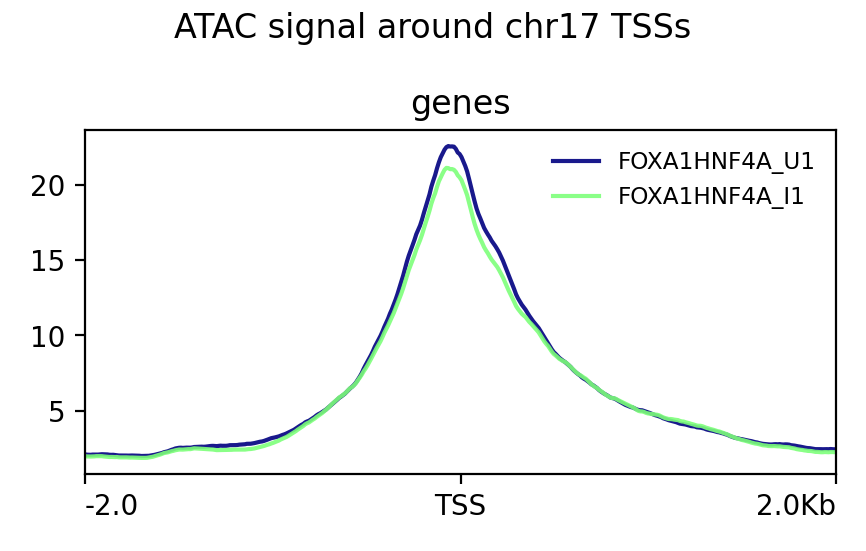

In [4]:
awk '$1 == "chr17"' $GENOME/hg38_tss_protein_coding.bed > tss_chr17.bed
echo "$(wc -l < tss_chr17.bed) protein-coding TSSs on chr17"

# reference-point: windows centred on one position per region (the TSS), 2 kb before (-b) and after (-a), in 10 bp bins
# --outFileNameMatrix: also write the matrix as text, so we can compute the enrichment score ourselves
# plotProfile --perGroup: one plot with both samples
computeMatrix reference-point -p $THREADS --referencePoint center -a 2000 -b 2000 --binSize 10 \
    -S FOXA1HNF4A_U1.bw FOXA1HNF4A_I1.bw --samplesLabel $SAMPLES -R tss_chr17.bed \
    -o tss_matrix.gz --outFileNameMatrix tss_matrix.tab 2> /dev/null
plotProfile -m tss_matrix.gz -o tss_profile.png --perGroup --refPointLabel TSS \
    --plotTitle "ATAC signal around chr17 TSSs" 2> /dev/null
cat tss_profile.png | display

Let's compute the score from the matrix: the mean signal in the central 100 bp divided by the mean signal in the outer 100 bp on both sides (the matrix has 400 bins of 10 bp per sample).

In [5]:
i=0
for s in $SAMPLES; do
    grep -v '^#' tss_matrix.tab | awk -v off=$(( i * 400 )) -v s=$s '
        NR > 1 { for (b = 1; b <= 400; b++) { v = $(off + b); if (v != "nan") { sum[b] += v } } }
        END { for (b = 196; b <= 205; b++) c += sum[b]
              for (b = 1; b <= 10; b++)    f += sum[b] + sum[400 - b + 1]
              printf "%s: TSS enrichment %.1f\n", s, (c / 10) / (f / 20) }'
    i=$(( i + 1 ))
done

FOXA1HNF4A_U1: TSS enrichment 9.6
FOXA1HNF4A_I1: TSS enrichment 9.5


You should get about 9.6 for FOXA1HNF4A_U1 and 9.5 for FOXA1HNF4A_I1. Both profiles have a strong peak at the TSS and both values are above ENCODE's ideal threshold of 7: good libraries, with the same signal-to-noise in both samples. Cultured cells usually give better ATAC-seq libraries than frozen tissue, where nuclei are harder to isolate intact.

Note that the induced sample is slightly *lower* at the TSS. That does not mean the libraries differ in quality: the coverage is normalised to the same total, and if FOXA1 and HNF4A open many new regions away from promoters, a slightly smaller share of the fragments falls at TSSs. We come back to this in Step 7.

Tools like [ataqv](https://github.com/ParkerLab/ataqv) compute these metrics (and more) in one go. Here is a genome-wide summary for all four samples, computed on the full data: read numbers from fastp, bowtie2 and Picard, the chrM fraction from `samtools idxstats`, the TSS enrichment from ataqv, and peaks and FRiP from MACS3 (Step 7):

In [6]:
column -t $BULK/data_generated/qc_summary.tsv

sample         read_pairs_M  kept_after_trim_%  aligned_%  duplicates_%  chrM_%  filtered_fragments_M  TSS_enrichment  peaks   FRiP
FOXA1HNF4A_U1  93.5          96.1               99.58      34.0          23.8    50.2                  6.0             92247   0.35
FOXA1HNF4A_U2  116.1         96.6               99.58      43.3          29.5    53.7                  6.1             105066  0.40
FOXA1HNF4A_I1  111.0         96.9               99.55      40.5          17.7    54.6                  5.7             140591  0.49
FOXA1HNF4A_I2  101.2         96.7               99.52      39.0          25.9    50.8                  6.0             129608  0.48


ataqv computes the TSS enrichment in its own way, so its values (about 6) are not directly comparable with ours or with the ENCODE thresholds; compare samples **with each other** using one tool. The four libraries are similar: almost all reads align, about 50 million fragments per sample remain after filtering, and the TSS enrichment is the same for all. Two numbers deserve a comment:

- **chrM**: 18-30% of the reads are mitochondrial. That is more than a good Omni-ATAC library (< 10%), but a common value for the original protocol on cultured cells; it costs sequencing depth, not quality, because we filter these reads out.
- **Duplicates**: 34-43% genome-wide (and 17-29% on chr17 in Step 4). The libraries were sequenced deeply (90-115 million pairs), so many fragments are sequenced more than once. Again a cost, not an artefact, as long as we remove them.

The most interesting difference is not technical: the **induced** samples have about 40% more peaks (130,000-140,000 versus 92,000-105,000) and a higher FRiP (0.48-0.49 versus 0.35-0.40), with the same TSS enrichment and depth. More of their fragments fall in peaks, and there are more peaks to fall in: a first hint that FOXA1 and HNF4A open many new regions.

## Step 7: Peak calling (MACS3)

Peaks are regions with significantly more fragments than expected from the local background. We use [MACS3](https://macs3-project.github.io/MACS/) `callpeak` in **paired-end mode** (`-f BAMPE`): MACS3 then uses the real fragments defined by each read pair, so there is no need to model or guess a fragment size. Unlike ChIP-seq, ATAC-seq has no input control: MACS3 estimates the local background from the sample itself (the [ChIP-seq practical](../chip-seq/index.md) calls peaks against an Input sample).

*You may have seen ATAC-seq peak calling with options like `--nomodel --shift -100 --extsize 200`. That trick is for single-end data (or for calling peaks on Tn5 cut sites only): it builds an artificial fragment around each read end. With paired-end data, `-f BAMPE` is the simpler and more accurate choice.*

Other options:

- `-g`: the effective genome size, used to compute the genome-wide background. Our reads only cover chr17, so we use the chr17 size from above.
- `--keep-dup all`: duplicates have already been removed, don't let MACS3 filter again.
- `-q 0.01`: report peaks with a false discovery rate (q-value) below 1%.

In [8]:
mkdir -p macs3
for s in $SAMPLES; do
    # -n: prefix of the output files; 2> macs3/$s.log: keep the log (it contains the fragment numbers)
    macs3 callpeak -f BAMPE -t ${s}.filtered.bam -n $s -g $GSIZE --keep-dup all -q 0.01 \
        --outdir macs3 2> macs3/${s}.log
done
wc -l macs3/*_peaks.narrowPeak

  5198 macs3/FOXA1HNF4A_I1_peaks.narrowPeak
  3520 macs3/FOXA1HNF4A_U1_peaks.narrowPeak
  8718 total


You should get about 3,500 peaks for FOXA1HNF4A_U1 and 5,200 for FOXA1HNF4A_I1 on chr17, close to the chr17 peaks of the genome-wide run (3,474 and 5,440). The induced sample has almost 50% more peaks, with about the same number of fragments and the same TSS enrichment: unlike a difference in library quality, this is a difference in biology. New regions have become accessible.

The `narrowPeak` format is a BED file with extra columns: name, score, strand, fold enrichment, -log10 p-value, -log10 q-value, and the position of the summit relative to the peak start. MACS3 also writes the summits separately (`_summits.bed`), which we will use in [part 2](part_2_consensus_peaks_macs_diff.ipynb).

In [10]:
# the 5 most significant peaks: sort on column 9 (-log10 q-value), g = general numeric, r = reverse
sort -k9,9gr macs3/FOXA1HNF4A_I1_peaks.narrowPeak | head -5
# peak width distribution
awk '{print $3 - $2}' macs3/FOXA1HNF4A_I1_peaks.narrowPeak | sort -n \
    | awk '{w[NR] = $1} END {printf "peak width: min %d, median %d, max %d bp\n", w[1], w[int(NR/2)], w[NR]}'

chr17	81860627	81861555	FOXA1HNF4A_I1_peak_5056	6674	.	17.2142	675.368	667.447	230
chr17	75288905	75290205	FOXA1HNF4A_I1_peak_4435	6590	.	18.3618	666.476	659.033	650
chr17	47649207	47650010	FOXA1HNF4A_I1_peak_2767	6545	.	17.6608	661.406	654.565	472
chr17	81238640	81239727	FOXA1HNF4A_I1_peak_4981	6368	.	18.8644	643.258	636.856	549
chr17	47895426	47896693	FOXA1HNF4A_I1_peak_2796	6278	.	16.3186	634.033	627.837	631
peak width: min 203, median 503, max 3876 bp


### Fraction of reads in peaks (FRiP)

FRiP is the fraction of all fragments that fall in peaks: a measure of signal-to-noise. ENCODE asks for FRiP > 0.2 (ideally > 0.3) for ATAC-seq; for transcription factor ChIP-seq, where peaks are fewer and narrower, 1% is already acceptable (see the [ChIP-seq practical](../chip-seq/index.md)). Let's compute it for both samples: we count all fragments, and the fragments whose first read overlaps a peak. (Counting only the first read slightly underestimates FRiP, as a fragment whose second read lies in a peak is missed, but it is simple and the same for both samples.)

In [11]:
for s in $SAMPLES; do
    # -c: only count; -f 64: only the first read of each pair, so we count fragments
    total=$(samtools view -c -f 64 ${s}.filtered.bam)
    # -L: only reads overlapping the regions of a BED file (here: the peaks); with -f 64, fragments whose first read is in a peak
    in_peaks=$(samtools view -c -f 64 -L macs3/${s}_peaks.narrowPeak ${s}.filtered.bam)
    awk -v s=$s -v p=$in_peaks -v t=$total 'BEGIN {printf "%s: %d of %d fragments in peaks, FRiP = %.2f\n", s, p, t, p/t}'
done

FOXA1HNF4A_U1: 661392 of 1550647 fragments in peaks, FRiP = 0.43
FOXA1HNF4A_I1: 1007564 of 1814127 fragments in peaks, FRiP = 0.56


FRiP is 0.43 for FOXA1HNF4A_U1 and 0.56 for FOXA1HNF4A_I1 on chr17, with each sample's own peaks: both well above ENCODE's 0.3. (chr17 is gene-rich, so its FRiP is a bit higher than the genome-wide values in the table above.)

FRiP depends on the peak set: with more peaks, more fragments fall in peaks. Here the induced sample has both more peaks and more of its fragments in them, because new regions opened. That is why [part 2](part_2_consensus_peaks_macs_diff.ipynb) computes FRiP again for all samples on one common set of regions, and why the choice of normalisation will matter in [part 3](part_3_diffbind_deseq2.ipynb).

## Step 8: Looking at the data

### In IGV

Download the two bigWig files (`*.bw`) and the two peak files (`macs3/*_peaks.narrowPeak`) and load them in [IGV](https://igv.org/app/) with genome **hg38**. Select both bigWig tracks, right-click and choose *Group Autoscale* so they share the same y-axis.

chr17 holds several liver genes that FOXA1 and HNF4A switch on in K562 cells (see the [bulk RNA-seq practical](../bulk-rna-seq/index.md); RNA counts from almost 0 to thousands):

| gene | role |
|---|---|
| *ASGR1* | asialoglycoprotein receptor, a classic hepatocyte surface marker |
| *VTN* | vitronectin, a plasma protein made by the liver |
| *SHBG* | sex hormone-binding globulin, secreted by hepatocytes |
| *SERPINF2* | alpha-2-antiplasmin, a liver-made protease inhibitor |
| *GCGR* | glucagon receptor |
| *CCL16* | a chemokine expressed almost only in the liver |
| *ACTG1* | gamma-actin, expressed in all cells: a useful "unchanged" control |

Browse to each gene. Where are the peaks: at the promoter, in introns, between genes? Are they present in the uninduced sample?

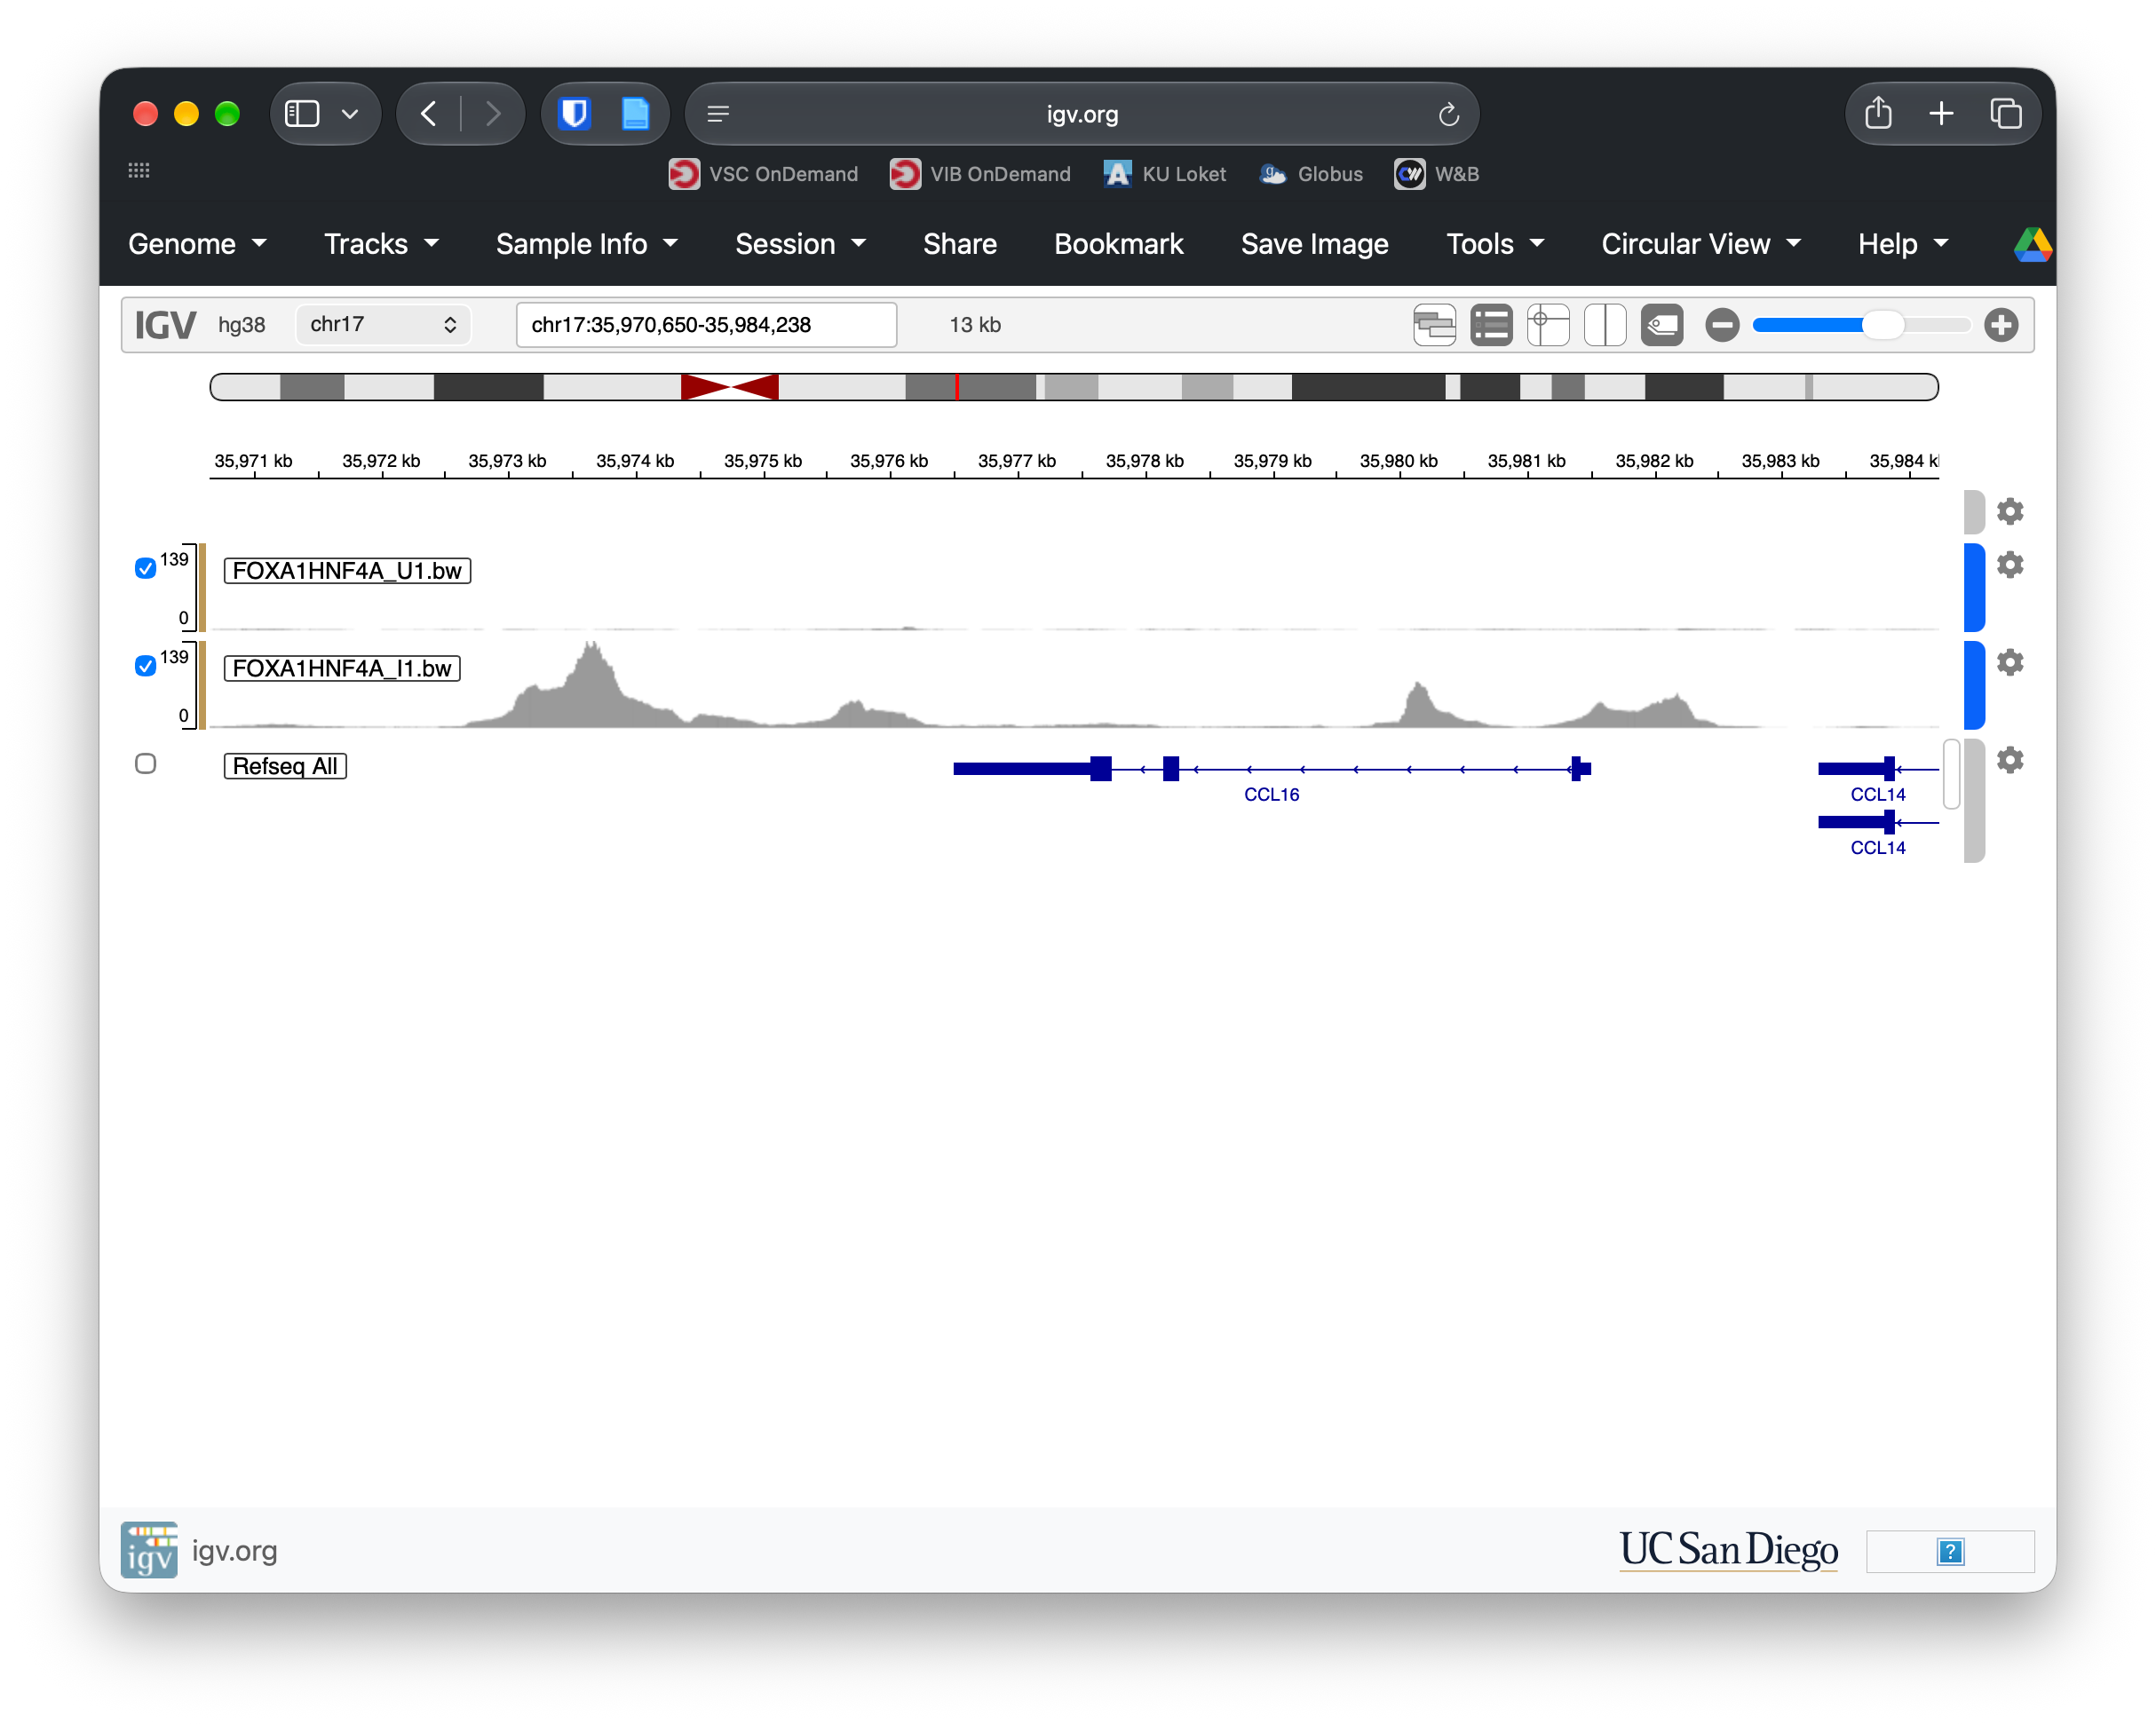

*CCL16* in IGV (chr17:35,970,650-35,984,238), with both coverage tracks on the same scale (*Group Autoscale*). *CCL16* lies on the minus strand, so its promoter is on the right. In the uninduced sample the whole region is flat: the gene is silent and its chromatin closed. In the induced sample four regions open: the promoter (a double peak), a region inside the gene, one just past its 3' end, and the strongest of all about 8 kb from the promoter, beyond the end of the gene. FOXA1 and HNF4A open not only the promoter but also regulatory regions around the gene, where nothing was accessible before.

### In numbers

We can also quantify the signal at the promoters of these genes. First, build a BED file with a window of ±1 kb around each TSS:

In [12]:
# grep -w: match whole words only (no partial matches inside longer gene names); awk: extend each TSS by 1 kb on both sides
grep -wE 'ASGR1|VTN|SHBG|SERPINF2|GCGR|CCL16|ACTG1' tss_chr17.bed \
    | awk 'BEGIN {OFS = "\t"} {print $1, $2 - 1000, $3 + 1000, $4}' > promoters.bed
cat promoters.bed

chr17	1741835	1743836	SERPINF2
chr17	7178563	7180564	ASGR1
chr17	7612945	7614946	SHBG
chr17	28372090	28374091	VTN
chr17	35980496	35982497	CCL16
chr17	81522846	81524847	ACTG1
chr17	81803131	81805132	GCGR


`multiBigwigSummary` computes the mean normalised coverage of each bigWig in each region:

In [13]:
# BED-file mode: one value per region of promoters.bed; --outRawCounts: write the values as a table
multiBigwigSummary BED-file -b FOXA1HNF4A_U1.bw FOXA1HNF4A_I1.bw --labels $SAMPLES --BED promoters.bed \
    -o promoters.npz --outRawCounts promoters_signal.tab 2> /dev/null
# add gene names and the induced / uninduced ratio
sort -k1,1 -k2,2n promoters.bed > promoters.sorted.bed
echo -e "gene\tU1\tI1\tratio"
grep -v '^#' promoters_signal.tab | sort -k1,1 -k2,2n | paste - promoters.sorted.bed \
    | awk 'BEGIN {OFS = "\t"} {printf "%s\t%.2f\t%.2f\t%.2f\n", $9, $4, $5, $5 / $4}'

gene	U1	I1	ratio
SERPINF2	1.00	5.01	5.02
ASGR1	0.87	3.81	4.39
SHBG	8.41	8.99	1.07
VTN	1.92	2.18	1.14
CCL16	1.20	19.74	16.49
ACTG1	3.68	2.43	0.66
GCGR	1.47	3.34	2.27


Four promoters gain accessibility after induction: *CCL16* about 16 times, *SERPINF2* 5 times, *ASGR1* 4 times and *GCGR* about 2 times. In IGV, *CCL16* is the clearest example: almost no signal in the uninduced sample, a strong peak in the induced one. The promoters of *SHBG* and *VTN* barely change: they are already accessible before induction, although the genes are silent. Opening a promoter is not the only way to switch on a gene; regions further away (enhancers) can matter too, and part 3 looks at all accessible regions near the induced genes, not just promoters.

Can we conclude that FOXA1 and HNF4A open these promoters? Not yet. We compared **one sample with one other sample**. Two cultures of the same condition also differ, and the library preparation adds technical variation. Without replicates we cannot tell whether a difference is larger than this normal variation. In addition, a ratio of normalised coverage gives no measure of uncertainty: a region with very few fragments can show a large ratio by chance.

Look at *ACTG1*, our "unchanged" control: it *drops* by about a third. This is a consequence of normalisation. RPGC scales each sample to the same total coverage. If the induced cells open thousands of new regions (Step 7: 50% more peaks), those regions take a share of the fragments, and every region that did not change gets a smaller share: it looks lower even though nothing happened there. The same holds for any normalisation on the total number of reads. Part 3 compares normalisation methods and shows how much this choice matters when one condition opens much more chromatin than the other.

That is why the experiment has **two replicates per condition**, and why the next notebooks:

- build one common set of regions (**consensus peaks**) for all four samples and count fragments in them, then try MACS3's differential mode ([part 2](part_2_consensus_peaks_macs_diff.ipynb));
- test for differences with statistical models that use the replicates, **DiffBind** and **DESeq2** ([part 3](part_3_diffbind_deseq2.ipynb)).

## Summary

| step | tool | output |
|---|---|---|
| read QC | FastQC | HTML reports |
| trimming | fastp | `*_trimmed_R?.fastq.gz` |
| alignment | bowtie2 + samtools | `*.sorted.bam` |
| duplicates | Picard MarkDuplicates | `*.markdup.bam` |
| filtering | samtools + bedtools | `*.filtered.bam` |
| ATAC QC | deepTools, samtools | fragment sizes, TSS enrichment, chrM fraction |
| coverage | deepTools bamCoverage | `*.bw` |
| peaks | MACS3 (BAMPE) | `macs3/*_peaks.narrowPeak`, FRiP |

The genome-wide versions of all these files, for all four samples, are in the subfolder `data_generated` of the course data. [Part 2](part_2_consensus_peaks_macs_diff.ipynb) starts from there.

## Exercises

1. For `FOXA1HNF4A_U1`, how many reads does each filter of Step 5 remove on its own? Use `samtools view -c` (count) on `FOXA1HNF4A_U1.markdup.bam` with one filter at a time (`-f 2`, `-f 1024`, `-q 30`, and `-L` with the blacklist). Which filter removes the most reads? (Our chr17 subset has no chrM reads; the genome-wide table shows what that filter removes.)
2. How many R1 reads of `FOXA1HNF4A_U1` contain the Nextera/Tn5 adapter? (Hint: the adapter starts with `CTGTCTCTTATA`; `awk 'NR % 4 == 2'` prints only the sequence lines of a FASTQ file, and `grep -c` counts matching lines.) How does this compare with the "Adapter Content" plot of FastQC and with the number of reads fastp trimmed?
3. Repeat the promoter quantification of Step 8 for other chr17 genes (`tss_chr17.bed` lists them all), for example 50 random ones (`shuf -n 50 tss_chr17.bed`). What is the median induced / uninduced ratio? What does this tell you about the drop of *ACTG1*?